# NIST TN 1822 — Verif.2.9: Group behaviours

15 m x 20 m room. Group 1: 4 agents at 1.25 m/s + 1 agent at 0.5 m/s, in the top zone. Group 2: 10 agents at 0.2 m/s, in the central zone. Group 1 arrivals at the exit should be within 10 s of each other.

Note: the original config had a custom `group_id` per distribution which was stripped (loader has no native group support). Group cohesion here must be verified by the arrival-spread check below; it is NOT enforced by the simulator.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:40 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles

## Load and run

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-2-9-groups.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
result = run_scenario(scenario, seed=42)
df = result.trajectory_dataframe()

Scenario: scenario_files/Nist-2-9-groups.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      240s
  Exits:         1
  Distributions: 3
  Stages:        0
  Zones:         0
  Journeys:      3
  Agents:        ~15
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 4 agents
    jps-distributions_1: 1 agents
    jps-distributions_2: 10 agents


## Scenario figure

Group 1 spawns in the top-right zone (four fast agents, one slow agent); Group 2 occupies the central strip.

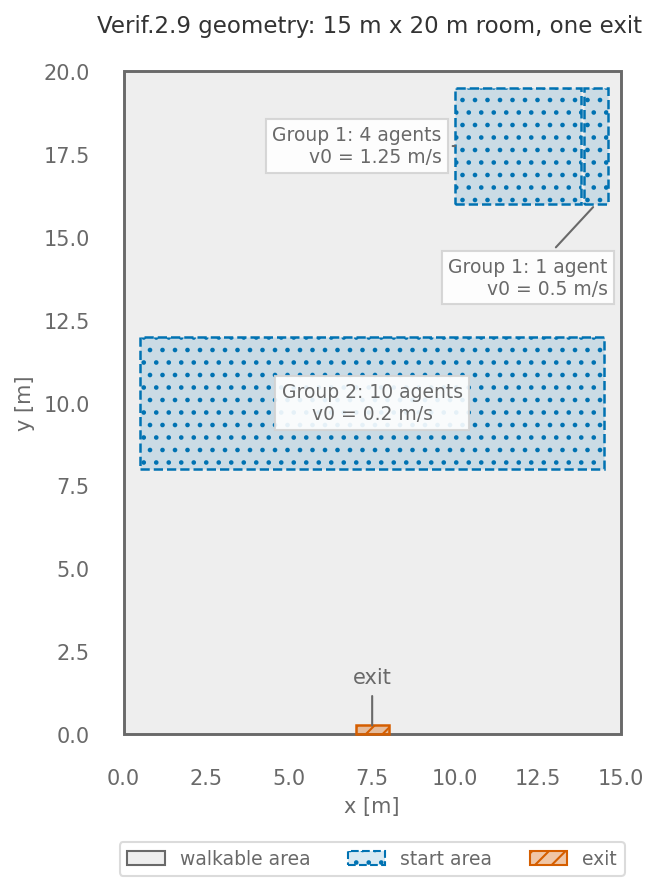

In [6]:
# Scenario geometry from the loaded ZIP.
BOX = {"facecolor": "white", "edgecolor": "lightgrey", "alpha": 0.9, "pad": 3}
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(5.6, 6.2))
    handles = vv_draw_scenario(ax, scenario)
    for name, dist in scenario.distributions.items():
        p = dist["parameters"]
        poly = Polygon(dist["coordinates"])
        group = "Group 2" if name == "jps-distributions_2" else "Group 1"
        n = p["number"]
        label = f"{group}: {n} agent{'s' if n != 1 else ''}\nv0 = {p['v0']} m/s"
        x0, y0, x1, y1 = poly.bounds
        if name == "jps-distributions_0":
            ax.annotate(label, xy=(x0, 0.5 * (y0 + y1)), xytext=(x0 - 0.4, 0.5 * (y0 + y1)),
                        ha="right", va="center", color="dimgrey", fontsize=9, bbox=BOX,
                        arrowprops={"arrowstyle": "-", "color": "dimgrey"})
        elif name == "jps-distributions_1":
            ax.annotate(label, xy=(0.5 * (x0 + x1), y0), xytext=(x1, y0 - 1.6),
                        ha="right", va="top", color="dimgrey", fontsize=9, bbox=BOX,
                        arrowprops={"arrowstyle": "-", "color": "dimgrey"})
        else:
            ax.text(poly.centroid.x, poly.centroid.y, label, ha="center", va="center",
                    color="dimgrey", fontsize=9, bbox=BOX)
    for ex in scenario.exits.values():
        e = Polygon(ex["coordinates"]).centroid
        ax.annotate("exit", xy=(e.x, e.y), xytext=(0, 22), textcoords="offset points",
                    ha="center", color="dimgrey", arrowprops={"arrowstyle": "-", "color": "dimgrey"})
    ax.set_title("Verif.2.9 geometry: 15 m x 20 m room, one exit", loc="left")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
    plt.show()

## Identify Group 1 agents and their arrival times

In [7]:
first = df.sort_values('frame').groupby('id').first()
group1_ids = first[(first.y >= 16.0) & (first.x >= 10.0)].index.tolist()
arrivals = []
for agent_id in group1_ids:
    sub = df[df.id == agent_id].sort_values('frame')
    reached = sub[(sub.y <= 0.3) & (sub.x >= 7.0) & (sub.x <= 8.0)]
    if len(reached):
        arrivals.append(reached.iloc[0].frame / result.frame_rate)
arrivals = np.array(arrivals)
print(f'group 1 size = {len(group1_ids)}; arrivals (s) = {arrivals}')

group 1 size = 5; arrivals (s) = []


## Result figure

Arrival time of the five Group 1 members, computed as in `tests/vv/test_nist.py` (last recorded frame per agent, Group 1 = five highest spawn y). The 10 s criterion is not met; the test is a strict `xfail` (issue #151).

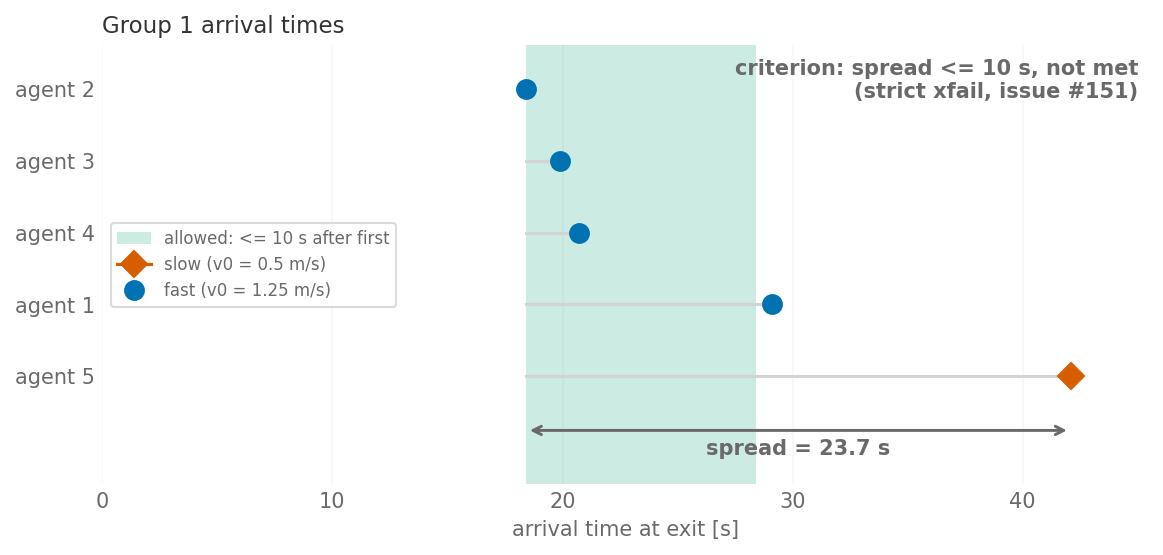

In [8]:
# Group 1 arrival times, computed as in tests/vv/test_nist.py::test_group1_arrives_together.
MAX_SPREAD_S = 10.0
by_agent = df.sort_values(["id", "frame"]).groupby("id")
first_pos = by_agent.first()
exit_time = by_agent["frame"].max() / result.frame_rate  # last recorded frame = absorbed at the exit
group1 = first_pos["y"].sort_values(ascending=False).head(5).index
slow_poly = Polygon(scenario.distributions["jps-distributions_1"]["coordinates"])
slow_id = min(group1, key=lambda i: slow_poly.distance(Point(first_pos.at[i, "x"], first_pos.at[i, "y"])))
v_fast = scenario.distributions["jps-distributions_0"]["parameters"]["v0"]
v_slow = scenario.distributions["jps-distributions_1"]["parameters"]["v0"]
arr = exit_time[group1].sort_values()
spread_g1 = float(arr.max() - arr.min())
met = spread_g1 <= MAX_SPREAD_S
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.axvspan(arr.min(), arr.min() + MAX_SPREAD_S, color=VV_GREEN, alpha=0.2, lw=0,
               label=f"allowed: <= {MAX_SPREAD_S:g} s after first")
    ypos = np.arange(len(arr))[::-1]
    for y, (i, ti) in zip(ypos, arr.items()):
        slow = i == slow_id
        ax.plot([arr.min(), ti], [y, y], color="lightgrey", lw=1.5, zorder=1)
        ax.plot(ti, y, marker="D" if slow else "o", ms=9, color=VV_RED if slow else VV_BLUE, zorder=3,
                label=f"slow (v0 = {v_slow:g} m/s)" if slow else None)
    ax.plot([], [], "o", color=VV_BLUE, ms=9, label=f"fast (v0 = {v_fast:g} m/s)")
    ax.set_yticks(ypos, [f"agent {i}" for i in arr.index])
    ax.set_xlabel("arrival time at exit [s]")
    ax.set_xlim(0, arr.max() * 1.08)
    ax.set_ylim(-1.5, len(arr) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.set_title("Group 1 arrival times", loc="left")
    y_dim = -0.75
    ax.annotate("", xy=(arr.max(), y_dim), xytext=(arr.min(), y_dim),
                arrowprops={"arrowstyle": "<->", "color": "dimgrey", "lw": 1.4})
    ax.text(0.5 * (arr.min() + arr.max()), y_dim - 0.12, f"spread = {spread_g1:.1f} s", ha="center", va="top",
            color="dimgrey", fontweight="semibold")
    ax.text(0.99, 0.97, f"criterion: spread <= {MAX_SPREAD_S:g} s, "
            + ("met" if met else "not met\n(strict xfail, issue #151)"),
            transform=ax.transAxes, ha="right", va="top", color="dimgrey", fontweight="semibold")
    ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.5), fontsize=8)
    plt.show()

## Acceptance

NIST Verif.2.9 requires Group 1 to reach the exit **together** — the arrival spread must be ≤ 10 s. The CollisionFreeSpeedModel has no group-cohesion model, so the 0.5 m/s member lags the 1.25 m/s members and the spread is ~24 s. The test (`test_nist.py`) encodes this criterion as a strict `xfail`; see issue #151.

In [9]:
if len(arrivals) >= 2:
    spread = float(arrivals.max() - arrivals.min())
    print(f'arrival spread = {spread:.2f} s (target <= 10 s)')
else:
    spread = float('nan')
    print('insufficient group 1 arrivals')
result.cleanup()

insufficient group 1 arrivals


1